# Project

## Introduction to the Project
The S&P 500 (Standard & Poor's 500) is a stock market index that tracks the performance of 500 of the largest publicly traded companies in the United States. It is widely regarded as one of the best representations of the U.S. stock market and economy. Over the long term, the S&P 500 has shown consistent growth, making it a key focus for long-term investors. However, it can also experience significant volatility in the short term.

In this project, we will make our first attempt to build a momentum-based strategy to trade the S&P 500 index. At the end of the project, you will have built a program that you can later expand and customise to suit your needs. We will use the python packages numpy, scipy and sqlite3, among others, in this project.

Tips: Review the code snippets that we went through during the course. Reorganize them and you are half-way done! Try experimenting with different configurations of the confidence interval, the lookback window and the forecast horizon. Be brave and experiment with different ways of deciding the position size. You may be surprised by your talent!

Re-organize your code from the exercises into a Python program that 
1. read prices from a database
2. calibrate a GBM model on each day when new prices are received.
3. forecast the price in e.g. 10 days and
   1. calculate the confidence interval of the forecast
   2. calculate the expected shortfall from the price forecast
4. code your trading signals using the price forecast and the expected shortfall.
5. store your postions into the *positions* table after each trade.
6. produce a 1-year backtest record from 2020-06-01 to 2021-05-31.

**Hint**

1. Collect all the code related to the GBM model into a class

In [19]:
import csv
import sqlite3
from contextlib import closing
from datetime import datetime

import numpy as np
from scipy.stats import norm

conn = sqlite3.connect("SP500.db")
cs = conn.cursor()


In [20]:
class GBM:
    def __init__(self):
        self.mu = np.nan
        self.sigma = np.nan
        self.rng = np.random.default_rng()
        
    def simulate(self, N, K, Dt, S0):
        traj = np.full((N+1, K), np.nan)
        traj[0, :] = S0

        Z = np.random.standard_normal((N, K))
        
        for i in range(N):
            traj[i+1, :] = traj[i, :] * np.exp(
                (self.mu - 0.5 * self.sigma**2) * Dt + 
                self.sigma * np.sqrt(Dt) * Z[i, :]
            )
        
        return traj

    def calibrate(self, trajectory, Dt):
        log_returns = np.diff(np.log(trajectory))
        self.sigma = np.std(log_returns, ddof=1) / np.sqrt(Dt)
        self.mu = np.mean(log_returns) / Dt + 0.5 * self.sigma**2
        
    def forecast(self, latest, T, confidence):
        mean = (self.mu - 0.5 * self.sigma**2) * T
        std = self.sigma * np.sqrt(T)
        z_score = norm.ppf((1 + confidence) / 2)
        lower = latest * np.exp(mean - z_score * std)
        upper = latest * np.exp(mean + z_score * std)
        median = latest * np.exp(mean)
        return (lower, median, upper)
        
    def expected_shortfall(self, T, confidence):
        mean = (self.mu - 0.5 * self.sigma**2) * T
        std = self.sigma * np.sqrt(T)
        alpha = 1 - confidence
        z_alpha = norm.ppf(alpha)
        es_ratio = np.exp(mean + 0.5 * std**2) * norm.cdf(z_alpha - std) / norm.cdf(z_alpha)
        return es_ratio

In [21]:
# test your code here
model = GBM()
model.mu = 0.3
model.sigma = 0.2
simulated = model.simulate(500, 1, 1/250, 100)
simulated = simulated[:, 0]

model2 = GBM()
model2.calibrate(simulated, 1/250)

print(F"Calibrated: mu = {model2.mu}, sigma = {model2.sigma}")



Calibrated: mu = 0.3681107677335481, sigma = 0.199256366579428


2. Write a function that prepares the database for trading, i.e.
   1. load the historical prices into the *prices* table
   2. create the *positions* table
   3. initialize the *positions* table with the your initial cash reserve. The initial *time_of_trade* can be any date before the earliest possible trading date.

    Call this function *prepare*.

In [22]:
def prepare():
    cs.execute("DROP TABLE IF EXISTS prices;")
    cs.execute("""
    CREATE TABLE prices (
        theday TEXT PRIMARY KEY,
        price REAL
        );
    """)

    with open('SP500.csv', 'r') as f:
        reader = csv.DictReader(f, delimiter='\t')
        for row in reader:
            date = list(row.values())[0]
            price = float(list(row.values())[1])

            cs.execute(
                "INSERT INTO prices (theday, price) VALUES (?, ?);",
                (date, price)
            )
    
    cs.execute("DROP TABLE IF EXISTS positions;")

    cs.execute("""
        CREATE TABLE positions (
            time_of_trade TEXT,
            symbol TEXT,
            quantity REAL,
            cash REAL
        );
    """)

    cs.execute("""
        INSERT INTO positions VALUES
        ('2020-01-01', 'SP500', 0, 100000.0);
    """)

    conn.commit()

In [23]:
# check whether you have loaded the prices correctly
prepare()
latest_prices = cs.execute("select * from prices order by theday desc limit 10")
for item in latest_prices:
    print(item)

('2021-05-31', 4203.60009765625)
('2021-05-30', 4210.10009765625)
('2021-05-28', 4206.0)
('2021-05-27', 4217.10009765625)
('2021-05-26', 4196.0)
('2021-05-25', 4197.5)
('2021-05-24', 4204.7001953125)
('2021-05-23', 4153.2998046875)
('2021-05-21', 4161.39990234375)
('2021-05-20', 4165.5)


3. Write a function that determines the trade size, i.e. how many units of the instrument you would like to own when the date is *which_day* and the price forecast of the instrument is *forecast* and the expected shortfall from the same forecast is *ES*.

In [32]:
def position_size(which_day, forecast, ES):
    cs.execute(f"""
        SELECT quantity, cash FROM positions
        WHERE time_of_trade < '{which_day}'
        ORDER BY time_of_trade DESC
        LIMIT 1;
    """)
    current_quantity, current_cash = cs.fetchall()[0]

    cs.execute(f"""
        SELECT price FROM prices
        WHERE theday <= '{which_day}'
        ORDER BY theday DESC
        LIMIT 1;
    """)
    current_price = cs.fetchall()[0][0]

    total_wealth = current_cash + current_quantity * current_price

    lower, median, upper = forecast

    expected_return = (median - current_price) / current_price
    if expected_return > 0 and ES < 1.0:
        risk_per_share = current_price * (1 - ES)
        max_risk = 0.02 * total_wealth
        shares_from_risk = max_risk / risk_per_share if risk_per_share > 0 else 0

         #limit position to use max 80% of total wealth
        max_position_value = 0.8 * total_wealth
        shares_from_capital = max_position_value / current_price

        target_shares = min(shares_from_risk, shares_from_capital)

    else:
        # If expected return is negative or ES indicates high risk, hold no position
        target_shares = 0

    return target_shares

4. Write a function that, for a given date, calibrates a GBM model to the data prior to that date and that forecasts the price in 10 days. Call this function *analyse*.

In [33]:
def analyse(which_day):
    lookback_days = 252

    # Get historical prices before which_day for calibration
    cs.execute(f"""
        SELECT price FROM prices
        WHERE theday < '{which_day}'
        ORDER BY theday DESC
        LIMIT {lookback_days};
    """)
    historical_prices = cs.fetchall()

    prices = np.array([p[0] for p in historical_prices])[::-1]

    cs.execute(f"""
        SELECT price FROM prices
        WHERE theday < '{which_day}'
        ORDER BY theday DESC
        LIMIT 1;
    """)
    latest_price = cs.fetchall()[0][0]

    model = GBM()
    Dt = 1/252 
    model.calibrate(prices, Dt)

    forecast_horizon = 10  # Forecast 10 days ahead
    T = forecast_horizon / 252  # Convert to years
    confidence = 0.95  # 95% confidence interval

    forecast = model.forecast(latest_price, T, confidence)

    ES = model.expected_shortfall(T, confidence)

    target_shares = position_size(which_day, forecast, ES)

    return target_shares

In [34]:
# Test the analyse function
test_dates = ['2021-05-09', '2021-05-14']
positions = [np.nan, np.nan]
for i in range(2):
    positions[i] = analyse(test_dates[i])
    print(F"{positions[i]} shares advised on {test_dates[i]}.")

10.771771885652768 shares advised on 2021-05-09.
0 shares advised on 2021-05-14.


5. The main loop of the program: Loop over the dates in the backtest period and use the *analyse* function to decide what to do on each day. Call this function *main*.

In [35]:
def main(begin_on):
    cs.execute(F"select theday from prices where theday >= '{begin_on}';")
    days = [d[0] for d in cs.fetchall()]
    asset = {
        'old': np.nan,
        'new': np.nan
    };
    cash = {
        'old': np.nan,
        'new': np.nan
    };
    cs.execute("delete from positions where time_of_trade > '2020-01-01';");
    for d in days:
        asset['new'] = analyse(d)
        cs.execute(F"""
        select quantity, cash from positions
        where time_of_trade < '{d}'
        order by time_of_trade desc
        limit 1;
        """);
        asset['old'], cash['old'] = cs.fetchall()[0];
        cs.execute(F"""
        select price from prices
        where theday <= '{d}'
        order by theday desc
        limit 1;
        """);
        latest = cs.fetchall()[0][0]
        trade_size = round(asset['new']) - round(asset['old']);
        if trade_size != 0:
            cash['new'] = cash['old'] - trade_size * latest;
            cs.execute(F"""
            insert into positions values
            ('{d}', 'SP500', {round(asset['new'])}, {cash['new']});
            """);
        conn.commit();



6. Connect to the database and create a *cursor* object associated with the connection. Share the connection and the cursor object across the program so that you don't have to connect to and disconnect from the database in every function of the program.

In [36]:
if __name__ == "__main__":
    with closing(sqlite3.connect("SP500.db")) as conn:
        with closing(conn.cursor()) as cs:
            prepare()
            main('2020-06-01')
    


In [37]:
# plot your track record
conn = sqlite3.connect("SP500.db")
cs = conn.cursor()

day1 = '2020-06-01'
day1_dt = datetime.strptime(day1, '%Y-%m-%d')

cs.execute(f"""
    select theday, quantity * price + cash as wealth
    from positions as PO
    join prices as PR
    on PO.time_of_trade = (
        select time_of_trade from positions
        where time_of_trade <= PR.theday
        order by time_of_trade desc limit 1
    )
    where theday >= '{day1}';
""")

records = cs.fetchall()

def calculate_T(record, day1_dt):
    theday, wealth = record
    theday_dt = datetime.strptime(theday, '%Y-%m-%d')
    T = (theday_dt - day1_dt).days
    return (T, wealth)

records = [calculate_T(record, day1_dt) for record in records]
W = np.asarray(records)

In [38]:
import matplotlib.pyplot as plt

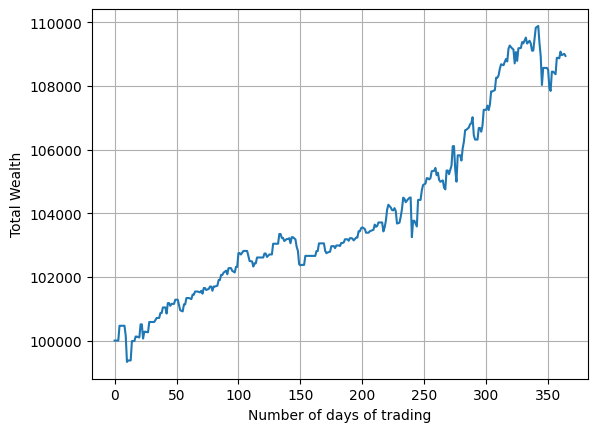

In [39]:
fig = plt.plot(W[:,0], W[:, 1])
plt.grid()
plt.xlabel("Number of days of trading")
plt.ylabel('Total Wealth');